# Stock Market Historical Data Analysis and Visualization

**Course:** EDAV (22ADC32N) - Course-End Project | **Dept.:** Information Technology, CBIT | **Sem:** III (2026-27)

**Objective:** Analyze historical stock price data to explore return, risk and trading-volume patterns using NumPy, Pandas and visualization tools, and develop insights into the factors that influence daily stock performance.

**Workflow (as required):** Data Cleaning -> Analysis -> Visualization -> Conclusion

| Titanic sample | This project (Stock Market) |
|---|---|
| Survived / Not survived | Up day / Down day (sign of daily return) |
| Age | Daily return %, Close price, Volume |
| Pclass, Sex | Year, Month, Weekday, Volume regime |
| Embarked port | Ticker (company / stock) |

**Notebook order:** Setup -> Data inspection -> **Q3 (cleaning, run first)** -> Q1 -> Q2 -> Q4 -> Q5 -> Final conclusion.

## 0. Environment Setup

```
pip install numpy pandas matplotlib seaborn yfinance
```
`yfinance` is only needed once, to download the dataset. If you already have a CSV (e.g. from Kaggle), skip the download cell and place it next to this notebook as `stock_data.csv` with columns: `Date, Ticker, Open, High, Low, Close, Volume`.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.max_columns', 30)
np.random.seed(42)

In [ ]:

CSV_PATH = 'stock_data.csv'
TICKERS  = ['RELIANCE.NS', 'TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'ICICIBANK.NS']
START, END = '2021-01-01', '2025-12-31'

if not os.path.exists(CSV_PATH):
    import yfinance as yf
    frames = []
    for t in TICKERS:
        d = yf.download(t, start=START, end=END, auto_adjust=True, progress=False)
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        d = d.reset_index()[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']]
        d.insert(1, 'Ticker', t.replace('.NS', ''))
        frames.append(d)
    pd.concat(frames, ignore_index=True).to_csv(CSV_PATH, index=False)
    print('Downloaded and saved ->', CSV_PATH)
else:
    print(CSV_PATH, 'already exists - using it.')

stock_data.csv already exists - using it.


## 1. Dataset Inspection

**Concept:** Before any analysis we inspect shape, data types, missing values, duplicates and basic statistics to find problems that must be fixed.

In [ ]:
raw = pd.read_csv(CSV_PATH)
print('Shape:', raw.shape)
print('Tickers:', raw['Ticker'].unique().tolist())
raw.info()
display(raw.head())

Shape: (6175, 7)
Tickers: ['RELIANCE', 'TCS', 'INFY', 'HDFCBANK', 'ICICIBANK']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6175 entries, 0 to 6174
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    6175 non-null   object 
 1   Ticker  6175 non-null   object 
 2   Open    6175 non-null   float64
 3   High    6175 non-null   float64
 4   Low     6175 non-null   float64
 5   Close   6175 non-null   float64
 6   Volume  6175 non-null   int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 337.8+ KB


,Date,Ticker,Open,High,Low,Close,Volume
0,2021-01-01,RELIANCE,897.273,901.335,894.565,897.047,10015175
1,2021-01-04,RELIANCE,900.477,902.192,888.246,898.559,24513534
2,2021-01-05,RELIANCE,888.697,895.287,882.830,887.388,24123091
3,2021-01-06,RELIANCE,887.298,887.343,859.879,863.986,46401468
4,2021-01-07,RELIANCE,866.807,877.865,859.879,862.587,32325918


In [ ]:
print('Missing values per column:')
display(raw.isnull().sum())
print('Fully duplicated rows        :', raw.duplicated().sum())
print('Duplicate (Date, Ticker) rows:', raw.duplicated(subset=['Date', 'Ticker']).sum())
display(raw.describe())

Missing values per column:


,0
Date,0
Ticker,0
Open,0
High,0
Low,0
Close,0
Volume,0


Fully duplicated rows        : 0
Duplicate (Date, Ticker) rows: 0


,Open,High,Low,Close,Volume
count,"6,175.000","6,175.000","6,175.000","6,175.000","6,175.000"
mean,"1,512.388","1,525.777","1,498.686","1,512.088","12,563,513.920"
std,897.196,905.018,889.156,896.775,"14,355,912.622"
min,493.554,508.180,491.060,500.987,0.000
25%,866.694,874.811,858.189,865.336,"4,723,218.500"
50%,"1,229.581","1,240.883","1,218.053","1,230.299","9,535,359.000"
75%,"1,543.601","1,557.141","1,530.979","1,545.904","15,754,265.000"
max,"4,228.901","4,243.918","4,169.755","4,208.338","445,342,100.000"


**Observation:** *(write in your own words after running - e.g. number of rows, tickers, date range, which columns have missing values/duplicates, whether Date is stored as text.)*

## Q3. Handling Missing Values and Anomalies (Imputation)  `[CO3, BL3]`

**Concept:** Stock data is a *time series*, so we cannot blindly use the median like Age in Titanic - a median price from 2021 would be meaningless in 2025. For **prices** we use *forward-fill then back-fill within each ticker* (a missing day takes the last known price). For **Volume** (not continuous in time) we use the *median of that ticker*. We also fix types, remove duplicates, treat impossible values as missing, and engineer features used in later questions.

In [ ]:
df = raw.copy()
price_cols = ['Open', 'High', 'Low', 'Close']
num_cols   = price_cols + ['Volume']

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print('Rows with invalid Date/Ticker:', df[['Date', 'Ticker']].isna().any(axis=1).sum())
df = df.dropna(subset=['Date', 'Ticker'])
n_dup = df.duplicated(subset=['Date', 'Ticker']).sum()
df = df.drop_duplicates(subset=['Date', 'Ticker'], keep='first')
print('Duplicates removed:', n_dup)

df = df.sort_values(['Ticker', 'Date']).reset_index(drop=True)

bad_price  = (df[price_cols] <= 0).any(axis=1)
bad_range  = df['High'] < df['Low']
bad_volume = df['Volume'] < 0
print('Non-positive prices :', bad_price.sum())
print('High < Low rows     :', bad_range.sum())
print('Negative volume rows:', bad_volume.sum())
df.loc[bad_price | bad_range, price_cols] = np.nan
df.loc[bad_volume, 'Volume'] = np.nan

print('\nMissing values BEFORE imputation:')
display(df[num_cols].isnull().sum())

Rows with invalid Date/Ticker: 0
Duplicates removed: 0
Non-positive prices : 0
High < Low rows     : 0
Negative volume rows: 0

Missing values BEFORE imputation:


,0
Open,0
High,0
Low,0
Close,0
Volume,0


In [ ]:
df[price_cols] = df.groupby('Ticker')[price_cols].transform(lambda s: s.ffill().bfill())
df['Volume']   = df.groupby('Ticker')['Volume'].transform(lambda s: s.fillna(s.median()))

assert df[num_cols + ['Date', 'Ticker']].isnull().sum().sum() == 0
print('Missing values AFTER imputation:', int(df[num_cols].isnull().sum().sum()))

Missing values AFTER imputation: 0


In [ ]:

df['Daily_Return'] = df.groupby('Ticker')['Close'].pct_change() * 100          # in %
df['Direction']    = np.select([df['Daily_Return'] > 0, df['Daily_Return'] < 0],
                               ['Up', 'Down'], default='Flat')
df['Year']    = df['Date'].dt.year
df['Month']   = df['Date'].dt.month
df['Weekday'] = df['Date'].dt.day_name()
df['MA20']    = df.groupby('Ticker')['Close'].transform(lambda s: s.rolling(20).mean())
df['MA50']    = df.groupby('Ticker')['Close'].transform(lambda s: s.rolling(50).mean())

ret = df.dropna(subset=['Daily_Return']).copy()
print('Rows in clean dataset:', len(df), '| rows used for return analysis:', len(ret))
display(df.head())

Rows in clean dataset: 6175 | rows used for return analysis: 6170


,Date,Ticker,Open,High,Low,Close,Volume,Daily_Return,Direction,Year,Month,Weekday,MA20,MA50
0,2021-01-01,HDFCBANK,670.871,672.268,661.832,663.906,"8,810,938.000",NaN,Flat,2021,1,Friday,NaN,NaN
1,2021-01-04,HDFCBANK,669.939,669.939,651.770,659.690,"15,740,192.000",-0.635,Down,2021,1,Monday,NaN,NaN
2,2021-01-05,HDFCBANK,661.180,666.561,656.428,664.674,"14,386,824.000",0.756,Up,2021,1,Tuesday,NaN,NaN
3,2021-01-06,HDFCBANK,668.541,670.871,658.338,661.809,"22,134,050.000",-0.431,Down,2021,1,Wednesday,NaN,NaN
4,2021-01-07,HDFCBANK,667.377,667.423,658.082,659.806,"19,894,842.000",-0.303,Down,2021,1,Thursday,NaN,NaN


Days with |z| > 4: 27


,Date,Ticker,Close,Daily_Return,Volume
1255,2021-02-01,ICICIBANK,579.106,12.439,"69,354,326.000"
1435,2021-10-25,ICICIBANK,809.640,10.852,"96,124,084.000"
310,2022-04-04,HDFCBANK,775.215,10.013,"97,450,970.000"
3035,2023-04-17,INFY,"1,129.578",-9.423,"53,171,705.000"
753,2024-01-17,HDFCBANK,736.105,-8.436,"170,145,236.000"
3102,2023-07-21,INFY,"1,211.446",-8.134,"45,548,305.000"
3220,2024-01-12,INFY,"1,486.219",7.934,"26,754,401.000"
3544,2025-05-12,INFY,"1,546.668",7.913,"11,372,857.000"


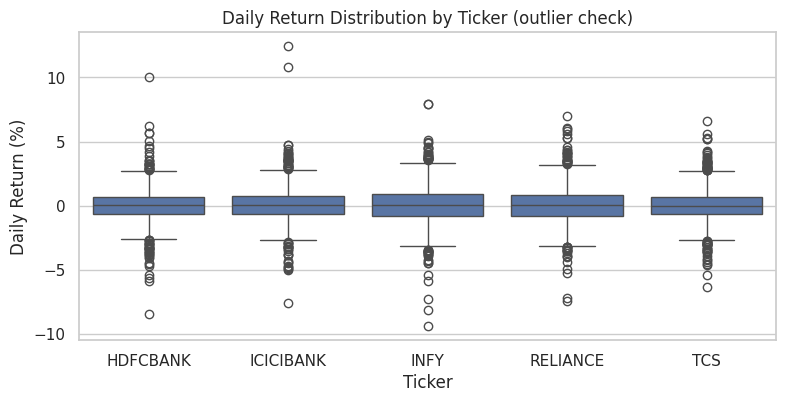

Focus stock: HDFCBANK


In [ ]:

ret['Z'] = ret.groupby('Ticker')['Daily_Return'].transform(lambda s: (s - s.mean()) / s.std())
outliers = ret[ret['Z'].abs() > 4]
print('Days with |z| > 4:', len(outliers))
display(ret.loc[ret['Daily_Return'].abs().nlargest(8).index, ['Date', 'Ticker', 'Close', 'Daily_Return', 'Volume']])

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=ret, x='Ticker', y='Daily_Return', ax=ax)
ax.set_title('Daily Return Distribution by Ticker (outlier check)')
ax.set_xlabel('Ticker'); ax.set_ylabel('Daily Return (%)')
plt.show()

FOCUS = df['Ticker'].unique()[0]
print('Focus stock:', FOCUS)

**Conclusion / Insight (Q3):** *(your words)* - mention how many values were missing/invalid, why forward-fill was chosen for prices instead of the median, how many outliers were found, and why they were kept (large moves are real market events, e.g. results days or market-wide shocks).

## Q1. NumPy Statistics - Average, Minimum and Maximum by Group  `[CO1, BL3]`

**Concept:** Using only NumPy array operations (boolean masks, `np.mean`, `np.min`, `np.max`) we compute statistics for the focus stock, grouped by (a) **market direction** (Up vs Down days - the analogue of Survived vs Not survived), (b) **volume regime** (high vs low volume days) and (c) **year**.

In [ ]:
f = ret[ret['Ticker'] == FOCUS]
returns   = f['Daily_Return'].to_numpy()
volume    = f['Volume'].to_numpy()
close     = f['Close'].to_numpy()
direction = f['Direction'].to_numpy()
years     = f['Year'].to_numpy()

rows = []
for d in ['Up', 'Down', 'Flat']:
    m = direction == d
    if m.sum() == 0:
        continue
    rows.append({'Direction': d, 'Days': int(m.sum()),
                 'Avg Return %': np.mean(returns[m]), 'Min Return %': np.min(returns[m]),
                 'Max Return %': np.max(returns[m]), 'Avg Volume': np.mean(volume[m])})
print(f'(a) Return and volume by direction - {FOCUS}')
display(pd.DataFrame(rows).set_index('Direction'))

high = volume > np.median(volume)
rows = []
for name, m in [('High volume', high), ('Low volume', ~high)]:
    rows.append({'Regime': name, 'Days': int(m.sum()),
                 'Avg |Return| %': np.mean(np.abs(returns[m])), 'Min Return %': np.min(returns[m]),
                 'Max Return %': np.max(returns[m]), 'Std Return %': np.std(returns[m])})
print(f'\n(b) Return behaviour by volume regime - {FOCUS}')
display(pd.DataFrame(rows).set_index('Regime'))
print('Correlation between Volume and |Return|:', round(np.corrcoef(volume, np.abs(returns))[0, 1], 3))


rows = []
for y in np.unique(years):
    m = years == y
    rows.append({'Year': int(y), 'Avg Close': np.mean(close[m]), 'Min Close': np.min(close[m]),
                 'Max Close': np.max(close[m]), 'Avg Daily Return %': np.mean(returns[m])})
print(f'\n(c) Close price statistics by year - {FOCUS}')
display(pd.DataFrame(rows).set_index('Year'))

(a) Return and volume by direction - HDFCBANK


,Days,Avg Return %,Min Return %,Max Return %,Avg Volume
Direction,,,,,
Up,638,0.953,0.003,10.013,"25,159,783.317"
Down,595,-0.939,-8.436,-0.003,"24,895,908.318"
Flat,1,0.000,0.000,0.000,0.000



(b) Return behaviour by volume regime - HDFCBANK


,Days,Avg |Return| %,Min Return %,Max Return %,Std Return %
Regime,,,,,
High volume,617,1.078,-8.436,10.013,1.545
Low volume,617,0.813,-3.665,5.055,1.091


Correlation between Volume and |Return|: 0.221

(c) Close price statistics by year - HDFCBANK


,Avg Close,Min Close,Max Close,Avg Daily Return %
Year,,,,
2021,706.192,636.885,790.141,0.028
2022,689.011,606.489,786.808,0.056
2023,767.506,700.628,827.405,0.030
2024,778.094,662.638,908.370,0.030
2025,925.452,790.950,996.420,0.055


**Conclusion / Insight (Q1):** *(your words)* - e.g. compare size of average up-day vs down-day moves, whether high-volume days are more volatile (see correlation), and which year had the highest average price / best average return.

## Q2. Pandas `groupby` - How Time Period and Stock Influence Returns  `[CO2, BL4]`

**Concept:** Like analysing survival by class and gender, we use `groupby` + aggregation to see how **year, month and weekday** influence average return, volatility (standard deviation) and the percentage of up days ("win rate"), and then compare the stocks overall.

In [ ]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']

def summarize(g):
    return g.agg(Avg_Return=('Daily_Return', 'mean'),
                 Volatility=('Daily_Return', 'std'),
                 Up_Day_Pct=('Daily_Return', lambda s: (s > 0).mean() * 100),
                 Avg_Volume=('Volume', 'mean'))

yearly  = summarize(ret.groupby(['Ticker', 'Year']))
weekday = summarize(ret.groupby('Weekday')).reindex(order).dropna(how='all')
monthly = summarize(ret.groupby('Month'))

print('Year-wise performance by ticker'); display(yearly)
print('\nWeekday effect (all tickers)');   display(weekday)
print('\nMonth-wise (all tickers)');       display(monthly)

Year-wise performance by ticker


Avg_Return  Volatility  Up_Day_Pct     Avg_Volume
Ticker    Year                                                   
HDFCBANK  2021       0.028       1.513      48.178 15,087,588.000
          2022       0.056       1.617      51.613 15,820,824.766
          2023       0.030       1.060      54.694 32,103,312.245
          2024       0.030       1.409      52.439 42,196,228.187
          2025       0.055       0.983      51.613 20,037,196.746
ICICIBANK 2021       0.157       1.963      49.798 17,534,258.680
          2022       0.088       1.456      53.226 12,992,431.915
          2023       0.054       0.980      52.245 16,474,214.616
          2024       0.114       1.308      55.691 15,358,688.760
          2025       0.027       1.024      48.387 10,398,973.980
INFY      2021       0.180       1.315      56.275  6,704,885.757
          2022      -0.067       1.743      52.016  6,510,381.093
          2023       0.031       1.468      48.163  6,519,121.947
          2024       0.103       1.441      51.220  7,023,484.220
          2025      -0.035       1.579      49.194  7,719,605.060
RELIANCE  2021       0.086       1.635      55.061 18,041,793.097
          2022       0.045       1.675      51.613 13,866,922.907
          2023       0.046       1.097      50.612 13,429,060.335
          2024      -0.013       1.443      51.220 13,245,182.809
          2025       0.104       1.226      51.210 11,215,720.794
TCS       2021       0.112       1.324      54.656  2,753,411.640
          2022      -0.039       1.467      48.790  2,344,872.790
          2023       0.083       1.143      51.837  1,933,396.286
          2024       0.048       1.332      48.374  2,413,507.317
          2025      -0.072       1.249      43.145  2,679,444.782


Weekday effect (all tickers)


,Avg_Return,Volatility,Up_Day_Pct,Avg_Volume
Weekday,,,,
Monday,0.088,1.624,53.173,"11,642,747.226"
Tuesday,0.094,1.272,52.320,"12,366,914.604"
Wednesday,0.061,1.271,51.440,"12,320,043.165"
Thursday,0.008,1.299,50.040,"13,372,100.166"
Friday,-0.000,1.492,49.344,"13,184,613.573"



Month-wise (all tickers)


,Avg_Return,Volatility,Up_Day_Pct,Avg_Volume
Month,,,,
1,-0.002,1.619,51.538,"13,864,614.335"
2,-0.026,1.649,45.941,"12,370,063.570"
3,0.099,1.495,52.200,"14,286,259.482"
4,-0.024,1.695,51.489,"15,791,239.655"
5,0.078,1.457,52.571,"12,602,760.507"
6,0.123,1.339,54.667,"12,303,877.621"
7,0.079,1.356,50.370,"12,839,063.935"
8,0.101,1.142,53.010,"12,061,676.548"
9,-0.066,1.166,48.679,"11,924,974.836"


In [ ]:

first_last = df.groupby('Ticker')['Close'].agg(First='first', Last='last')
overall = pd.DataFrame({
    'Total_Return_%': (first_last['Last'] / first_last['First'] - 1) * 100,
    'Avg_Daily_Return_%': ret.groupby('Ticker')['Daily_Return'].mean(),
    'Annual_Volatility_%': ret.groupby('Ticker')['Daily_Return'].std() * np.sqrt(252),
    'Up_Day_%': ret.groupby('Ticker')['Daily_Return'].apply(lambda s: (s > 0).mean() * 100),
})
overall['Return_per_Risk'] = overall['Avg_Daily_Return_%'] * 252 / overall['Annual_Volatility_%']
display(overall.sort_values('Total_Return_%', ascending=False))

,Total_Return_%,Avg_Daily_Return_%,Annual_Volatility_%,Up_Day_%,Return_per_Risk
Ticker,,,,,
ICICIBANK,163.137,0.088,22.083,51.864,1.005
RELIANCE,70.862,0.054,22.725,51.945,0.595
HDFCBANK,46.825,0.040,21.244,51.702,0.475
INFY,46.143,0.042,24.075,51.378,0.442
TCS,24.114,0.026,20.757,49.352,0.316


**Conclusion / Insight (Q2):** *(your words)* - which year was best/worst, whether any weekday or month shows consistently higher returns (and whether the difference is large or just noise), which stock gave the best return and which had the best return for the risk taken.

## Q4. Group by Ticker and Direction - Descriptive Statistics  `[CO4, BL4]`

**Concept:** Equivalent of grouping by `['Embarked','Survived']`: we use `groupby(['Ticker','Direction'])` with `count` and `mean` aggregations to compare how often each stock moves up or down and how large the moves are.

In [ ]:
grp = (ret[ret['Direction'].isin(['Up', 'Down'])]
       .groupby(['Ticker', 'Direction'])
       .agg(Days=('Daily_Return', 'count'),
            Avg_Return=('Daily_Return', 'mean'),
            Avg_Volume=('Volume', 'mean'),
            Largest_Move=('Daily_Return', lambda s: s.abs().max())))
display(grp)

counts = ret.pivot_table(index='Ticker', columns='Direction', values='Daily_Return', aggfunc='count').fillna(0)
counts['Up_Probability_%'] = counts['Up'] / (counts['Up'] + counts['Down']) * 100
print('\nUp/Down day counts and probability of an up day')
display(counts)

print('\nFull descriptive statistics of daily return (%) by ticker')
display(ret.groupby('Ticker')['Daily_Return'].describe())

Days  Avg_Return     Avg_Volume  Largest_Move
Ticker    Direction                                               
HDFCBANK  Down        595      -0.939 24,895,908.318         8.436
          Up          638       0.953 25,159,783.317        10.013
ICICIBANK Down        592      -0.921 13,948,383.728         7.634
          Up          640       1.022 15,116,689.411        12.439
INFY      Down        598      -1.100  6,976,479.418         9.423
          Up          634       1.120  6,830,621.997         7.934
RELIANCE  Down        591      -1.040 13,941,444.262         7.485
          Up          641       1.062 14,008,235.410         7.019
TCS       Down        624      -0.915  2,466,596.881         6.353
          Up          609       0.990  2,388,131.148         6.633


Up/Down day counts and probability of an up day


Direction,Down,Flat,Up,Up_Probability_%
Ticker,,,,
HDFCBANK,595,1,638,51.744
ICICIBANK,592,2,640,51.948
INFY,598,2,634,51.461
RELIANCE,591,2,641,52.029
TCS,624,1,609,49.392



Full descriptive statistics of daily return (%) by ticker


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
HDFCBANK,"1,234.000",0.040,1.338,-8.436,-0.647,0.053,0.705,10.013
ICICIBANK,"1,234.000",0.088,1.391,-7.634,-0.635,0.057,0.763,12.439
INFY,"1,234.000",0.042,1.517,-9.423,-0.822,0.044,0.910,7.934
RELIANCE,"1,234.000",0.054,1.432,-7.485,-0.796,0.065,0.814,7.019
TCS,"1,234.000",0.026,1.308,-6.353,-0.665,-0.019,0.697,6.633


**Conclusion / Insight (Q4):** *(your words)* - which ticker has the highest/lowest probability of an up day, whether average gains are bigger than average losses for each stock, and which stock is riskiest (largest move, widest spread).

## Q5. Bar Plots, Line Plots and Heatmaps  `[CO5, BL5]`

**Concept:** Visualizations make the patterns from Q1-Q4 easy to interpret: line plots for price growth, bar plots for yearly and weekday performance, and heatmaps for monthly returns, up/down counts and correlation between stocks.

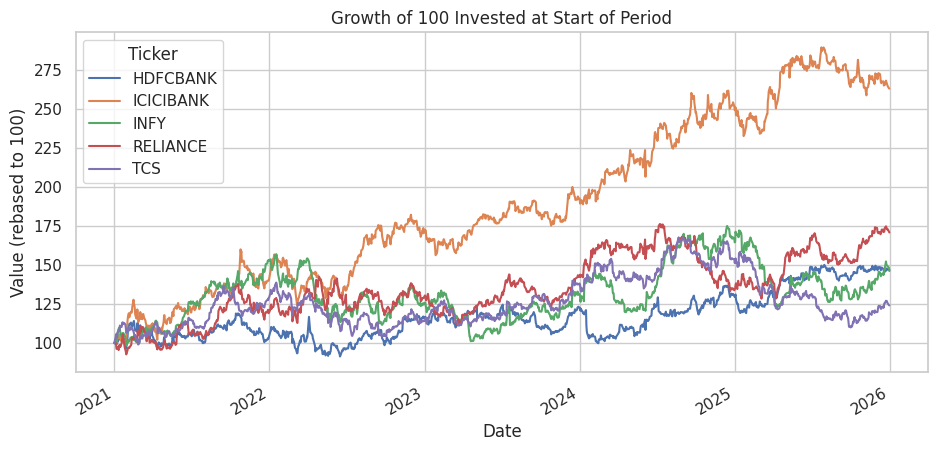

In [ ]:

close_pivot = df.pivot(index='Date', columns='Ticker', values='Close')
rebased = close_pivot.apply(lambda s: s / s.dropna().iloc[0] * 100)

fig, ax = plt.subplots(figsize=(11, 5))
rebased.plot(ax=ax, linewidth=1.5)
ax.set_title('Growth of 100 Invested at Start of Period')
ax.set_xlabel('Date'); ax.set_ylabel('Value (rebased to 100)')
ax.legend(title='Ticker')
plt.show()

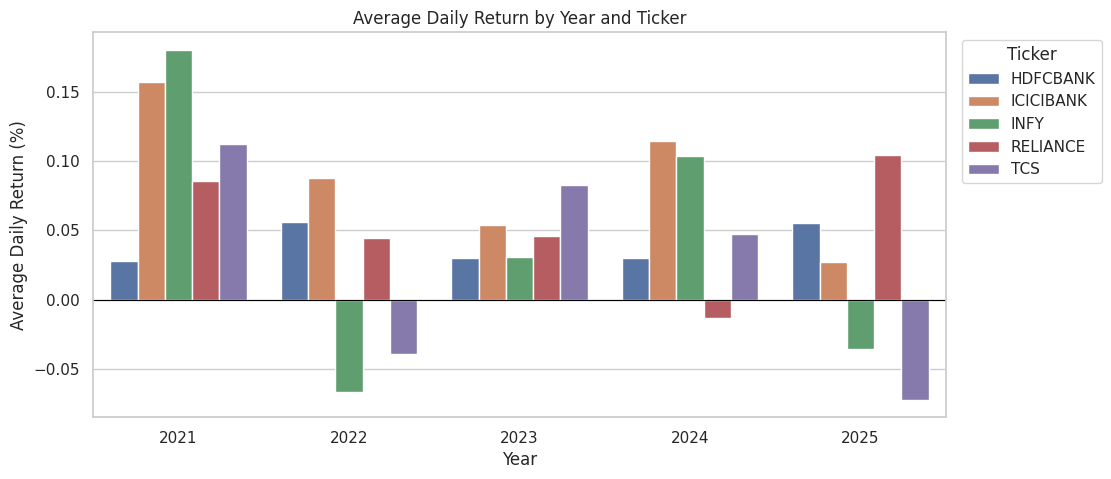

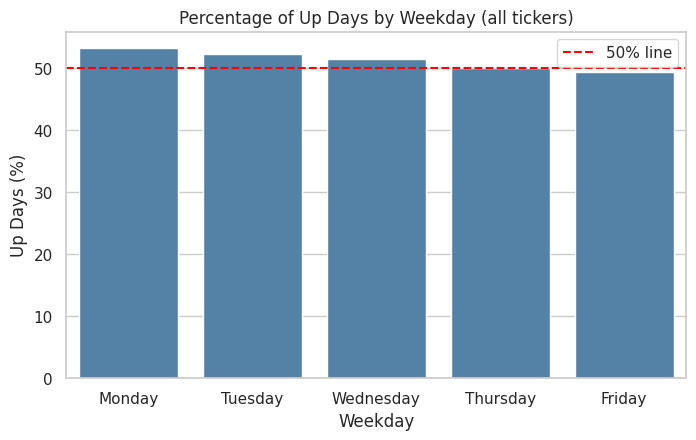

In [ ]:

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=yearly.reset_index(), x='Year', y='Avg_Return', hue='Ticker', ax=ax)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Average Daily Return by Year and Ticker')
ax.set_xlabel('Year'); ax.set_ylabel('Average Daily Return (%)')
ax.legend(title='Ticker', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=weekday.index, y=weekday['Up_Day_Pct'], ax=ax, color='steelblue')
ax.axhline(50, color='red', linestyle='--', label='50% line')
ax.set_title('Percentage of Up Days by Weekday (all tickers)')
ax.set_xlabel('Weekday'); ax.set_ylabel('Up Days (%)')
ax.legend()
plt.show()

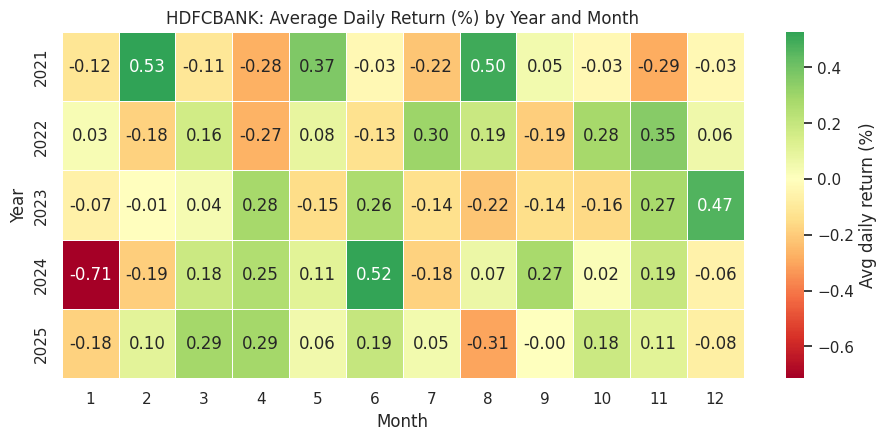

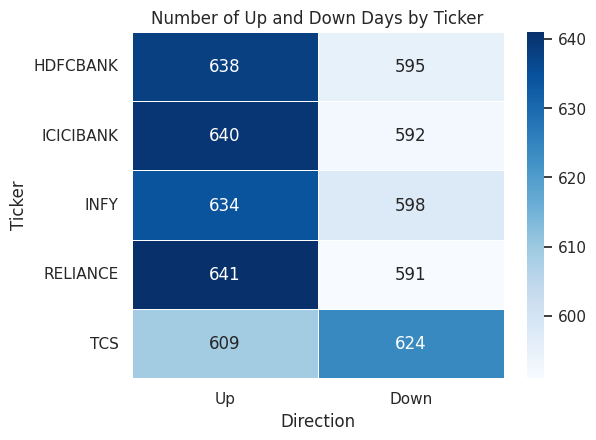

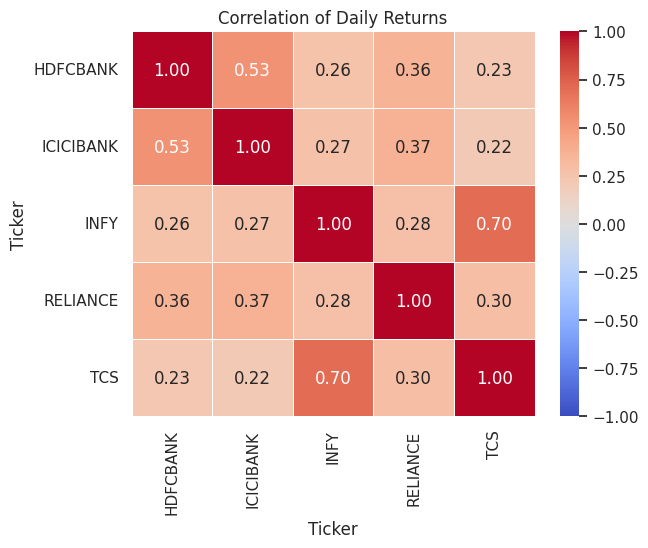

In [ ]:

pt = ret[ret['Ticker'] == FOCUS].pivot_table(index='Year', columns='Month', values='Daily_Return', aggfunc='mean')
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(pt, annot=True, fmt='.2f', cmap='RdYlGn', center=0, linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Avg daily return (%)'})
ax.set_title(f'{FOCUS}: Average Daily Return (%) by Year and Month')
ax.set_xlabel('Month'); ax.set_ylabel('Year')
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(counts[['Up', 'Down']], annot=True, fmt='.0f', cmap='Blues', linewidths=0.5, ax=ax)
ax.set_title('Number of Up and Down Days by Ticker')
ax.set_xlabel('Direction'); ax.set_ylabel('Ticker')
plt.show()

corr = ret.pivot(index='Date', columns='Ticker', values='Daily_Return').corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title('Correlation of Daily Returns')
plt.show()

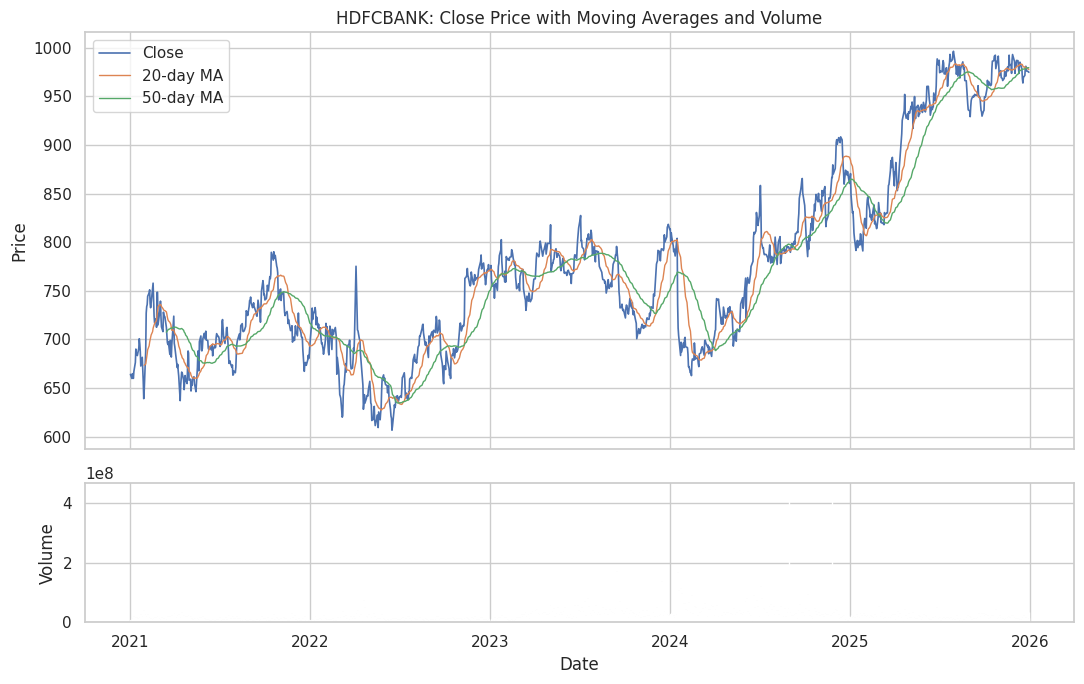

In [ ]:

f_all = df[df['Ticker'] == FOCUS]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(f_all['Date'], f_all['Close'], label='Close', linewidth=1.2)
ax1.plot(f_all['Date'], f_all['MA20'], label='20-day MA', linewidth=1)
ax1.plot(f_all['Date'], f_all['MA50'], label='50-day MA', linewidth=1)
ax1.set_title(f'{FOCUS}: Close Price with Moving Averages and Volume')
ax1.set_ylabel('Price'); ax1.legend()
ax2.bar(f_all['Date'], f_all['Volume'], color='gray', width=1.0)
ax2.set_xlabel('Date'); ax2.set_ylabel('Volume')
plt.tight_layout()
plt.show()

**Conclusion / Insight (Q5):** *(your words)* - which stock grew most in the line plot, which years were strongest in the bar plot, whether any weekday is clearly better than 50%, which months look consistently green/red in the heatmap, and how strongly the stocks move together (diversification point from the correlation heatmap).

## Auto-generated Key Facts (use as a cross-check for your conclusions)

In [ ]:
best  = overall['Total_Return_%'].idxmax()
worst = overall['Total_Return_%'].idxmin()
risky = overall['Annual_Volatility_%'].idxmax()
up_t  = counts['Up_Probability_%'].idxmax()
best_wd = weekday['Avg_Return'].idxmax()
worst_wd = weekday['Avg_Return'].idxmin()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()

print(f'Date range                 : {df.Date.min().date()} to {df.Date.max().date()}')
print(f'Best / worst total return  : {best} ({overall.loc[best, "Total_Return_%"]:.1f}%) / {worst} ({overall.loc[worst, "Total_Return_%"]:.1f}%)')
print(f'Most volatile stock        : {risky} ({overall.loc[risky, "Annual_Volatility_%"]:.1f}% annualised)')
print(f'Highest up-day probability : {up_t} ({counts.loc[up_t, "Up_Probability_%"]:.1f}%)')
print(f'Best / worst weekday       : {best_wd} / {worst_wd}')
print(f'Most correlated pair       : {pairs.idxmax()} ({pairs.max():.2f}); least: {pairs.idxmin()} ({pairs.min():.2f})')

Date range                 : 2021-01-01 to 2025-12-30
Best / worst total return  : ICICIBANK (163.1%) / TCS (24.1%)
Most volatile stock        : INFY (24.1% annualised)
Highest up-day probability : RELIANCE (52.0%)
Best / worst weekday       : Tuesday / Friday
Most correlated pair       : ('INFY', 'TCS') (0.70); least: ('ICICIBANK', 'TCS') (0.22)


## Final Conclusion

*(Write 5-8 lines in your own words summarising: data quality issues and how you fixed them, return and risk differences between stocks, time-based patterns (year/weekday/month), role of volume, correlation/diversification, and limitations - past performance does not predict future returns, short data window, prices only (no news/fundamentals).)*

**Limitations & Future Work:** add more stocks/sectors, include a benchmark index (NIFTY 50), try risk-adjusted metrics (Sharpe ratio), and build simple forecasting models.